LIBRARY

In [130]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import seaborn as sns
import matplotlib.pyplot as plt

FUNCTION

In [131]:
# Fungsi untuk membersihkan data
def clean(data):
    df = pd.DataFrame(columns=['Year', 'Age', 'Female', 'Male', 'Total'])

    for i in range(len(data)):
        row = data.iloc[i, 0].split()
        df.loc[len(df)] = row

    for column in df.columns:
        if df[column].dtype == "object":
            df[column] = df[column].str.replace(r'[+-]', '', regex=True)
    
    for column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce')  # Jika gagal, data menjadi NaN

    df = df.fillna(0)
    df = df.drop_duplicates(subset=["Year", "Age"]).reset_index(drop=True)
    return df

# Fungsi untuk smoothing menggunakan metode Whittaker-Henderson
def whittaker_henderson(y, lambda_, d=2):
    n = len(y)
    E = sp.eye(n)
    D = sp.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
    
    # Matriks penalti
    P = lambda_ * D.T @ D
    
    # Menyelesaikan sistem persamaan
    Z = E + P
    z = spla.spsolve(Z, y)
    
    return z

DATA

In [132]:
# Membaca dan membersihkan data
italy_death = clean(pd.read_csv("Data pembanding/Italy/Italy , Deaths (period 1x1).txt", delimiter="\t"))
italy_population = clean(pd.read_csv("Data pembanding/Italy/Italy , Population size (abridged).txt", delimiter="\t"))

BACKUP

In [133]:
backup_bel_death = italy_death.copy()
backup_bel_population = italy_population.copy()

# Mengatur data agar memiliki panjang yang sama
selisih = len(italy_population) - len(italy_death)
backup_bel_population = backup_bel_population[:-selisih].reset_index(drop=True)

backup_bel_death = backup_bel_death[backup_bel_death["Age"] < 104].reset_index(drop=True)
backup_bel_population = backup_bel_population[backup_bel_population["Age"] < 104].reset_index(drop=True)


FEMALE

WHITE TAKER

In [134]:
# Menghitung qx untuk perempuan
qx_female = (backup_bel_death["Female"] / backup_bel_population["Female"]).fillna(0)

# Smoothing qx menggunakan Whittaker-Henderson
qx_head_female = qx_female.head(111)
qx_1872_female = qx_head_female[:-7]
smoothed_qx_female = whittaker_henderson(qx_1872_female, lambda_=10)
smoothed_qx_female

array([0.22823646, 0.16968367, 0.11709967, 0.07518509, 0.04480281,
       0.0247071 , 0.01262449, 0.00620222, 0.00347223, 0.00294605,
       0.00354608, 0.00457082, 0.00555839, 0.00636554, 0.00692921,
       0.00731522, 0.00761167, 0.0078952 , 0.00821041, 0.00861125,
       0.00904824, 0.00954668, 0.00997198, 0.0103259 , 0.01059356,
       0.01084018, 0.01112031, 0.01143201, 0.01174291, 0.01205788,
       0.01226627, 0.01258788, 0.01273264, 0.01276554, 0.01270178,
       0.01267871, 0.01285831, 0.01319839, 0.01353386, 0.01382121,
       0.0139419 , 0.01426751, 0.01440638, 0.01440696, 0.01423217,
       0.01412075, 0.0143386 , 0.01480123, 0.01541382, 0.01623326,
       0.01721401, 0.01876616, 0.0203057 , 0.02177548, 0.0230358 ,
       0.02444128, 0.02636284, 0.02872431, 0.03123125, 0.0339422 ,
       0.03676669, 0.04084773, 0.04491867, 0.04884328, 0.05253099,
       0.05671075, 0.06214793, 0.06819516, 0.07406671, 0.07979577,
       0.08569313, 0.09490199, 0.10521493, 0.11607408, 0.12620

In [135]:
qx_1872_female

0      0.287924
1      0.157002
2      0.078722
3      0.054099
4      0.034526
         ...   
99     0.645666
100    0.709812
101    0.778598
102    0.752941
103    0.894118
Name: Female, Length: 104, dtype: float64

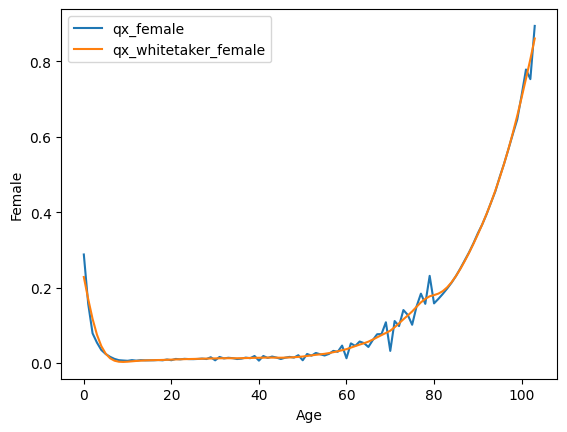

In [136]:
age = backup_bel_death["Age"].head(104)

sns.lineplot(x = age, y = qx_1872_female, label = "qx_female")
sns.lineplot(x = age, y = smoothed_qx_female, label = "qx_whitetaker_female")
plt.legend()

LAMBDA

In [137]:
dx_female = backup_bel_death["Female"]
L_female = backup_bel_population["Female"]
smoothed_double_female = np.tile(smoothed_qx_female, 150) 
t = backup_bel_death["Year"]
t0 = 1872

lambda_values = []

# Calculate lambda for each subset (assuming 104 groups based on the dataset)
for j in range(104):
    # Compute numerator for each individual lambda
    numerator_list = []
    for i in range(j, len(dx_female), 104):
        if dx_female[i] > 0 and (L_female[i] * smoothed_double_female[i]) > 0:
            log_value = np.log(dx_female[i] / (L_female[i] * smoothed_double_female[i]))
            numerator_list.append(log_value * (t.iloc[i] - t0))
        else:
            numerator_list.append(0)  # Avoid division by zero or negative values

    numerator = np.sum(numerator_list)
    denominator = np.sum((t.iloc[j::104] - t0) ** 2)  # Calculate denominator for this subset

    if denominator != 0:
        lambda_female = -numerator / denominator
    else:
        lambda_female = 0  # Set to 0 if the denominator is zero

    lambda_values.append(lambda_female)

lambda_values


[0.025628088529779856,
 0.04509446667565622,
 0.04766004301899812,
 0.04669908491375103,
 0.04416125144351945,
 0.04006872962398657,
 0.03418295096583179,
 0.028824651194767247,
 0.024152950790504377,
 0.022937599945466253,
 0.02494717377204875,
 0.0273433160525561,
 0.0285938279540875,
 0.029170199374680846,
 0.02845955210675293,
 0.027913238863083476,
 0.02737107166159002,
 0.02697019758945613,
 0.026348202160709825,
 0.02651347313157704,
 0.026587518850973053,
 0.026947893776565757,
 0.02719362738707558,
 0.02737731865738341,
 0.0272657057258386,
 0.027105849849774512,
 0.027255208216710798,
 0.027153644990809748,
 0.027073233078108116,
 0.02687068321314506,
 0.026548558950633544,
 0.026443880104794166,
 0.025912468947773222,
 0.025421027989652106,
 0.024703047032841218,
 0.024041097960146793,
 0.02355628337937924,
 0.023193908087651906,
 0.02261382676124127,
 0.022313196515165164,
 0.02147434551546724,
 0.02114403016532193,
 0.02044713866366757,
 0.01975971694027836,
 0.01888016858

ALPHA

In [138]:
# Initialize a list to store alpha values per year
alpha_list = []

# Assuming 'tahun' is an array of years relative to t0
tahun = np.arange(0, 150)

for i in range(150):  # Loop over each year
    numerator_alpha = 0
    denominator_alpha = 0
    for j in range(104):  # Loop over each age group
        dx = dx_female[j]
        Lx = L_female[j]
        qx_t0 = smoothed_qx_female[j]
        lambda_x = lambda_values[j]  # Use age-specific lambda

        if Lx * qx_t0 > 0:
            logika1 = dx / (Lx * qx_t0)
            logika2 = np.exp(-lambda_x * tahun[i])
            numerator_alpha += logika1 * logika2
            denominator_alpha += logika2 ** 2

    # Avoid division by zero
    if denominator_alpha != 0:
        alpha_t = numerator_alpha / denominator_alpha
    else:
        alpha_t = 0
        
    alpha_list.append(alpha_t)

# Convert alpha_list to a pandas Series
alpha_series = pd.Series(alpha_list, index=tahun, name='alpha')
alpha_series

0      1.042478
1      1.060977
2      1.079452
3      1.097895
4      1.116298
         ...   
145    2.467824
146    2.472888
147    2.477965
148    2.483055
149    2.488158
Name: alpha, Length: 150, dtype: float64

QX

In [139]:
# Initialize a list to store qx values
qx_female = []

for j in range(104):  # Loop over each year
    for i in range(150):  # Loop over each age group
        alpha_t = alpha_series.iloc[i]
        qx_t0 = smoothed_qx_female[j]
        lambda_x = lambda_values[j]  # Use age-specific lambda
        exponent = np.exp(-lambda_x * tahun[i])
        qx_t = alpha_t * qx_t0 * exponent
        qx_female.append(qx_t)

qx_female


[0.23793157584643035,
 0.23602659197101636,
 0.2340604407031574,
 0.23203595962212134,
 0.22995598455305857,
 0.22782334464513146,
 0.22564085768088693,
 0.22341132561458862,
 0.22113753033678485,
 0.21882222966204726,
 0.2164681535365335,
 0.2140780004618277,
 0.21165443413134574,
 0.20920008027548628,
 0.2067175237116099,
 0.20420930559488287,
 0.20167792086596562,
 0.1991258158914916,
 0.1965553862932592,
 0.19396897496201454,
 0.1913688702516851,
 0.18875730434986798,
 0.18613645182034583,
 0.1835084283133342,
 0.18087528943911438,
 0.1782390298006227,
 0.1756015821804966,
 0.1729648168779907,
 0.17033054119108476,
 0.1677004990390122,
 0.16507637072034675,
 0.16245977280168675,
 0.15985225813188467,
 0.15725531597668457,
 0.154670372268545,
 0.15209878996635331,
 0.14954186951966858,
 0.14700084943208372,
 0.14447690691824583,
 0.14197115864905221,
 0.13948466157952288,
 0.13701841385384675,
 0.13457335578211993,
 0.1321503708833181,
 0.12975028698909585,
 0.1273738774030637,
 0.1

In [140]:
ages = backup_bel_death['Age'].unique() 

# Create a DataFrame for the normalized qx values
qx_df = pd.DataFrame({
    'Age': np.repeat(ages, 150),
    'Year': np.tile(tahun + t0, len(ages)),  # Adjust years to actual years
    'qx': qx_female
})

tabel = pd.merge(backup_bel_death[['Age', 'Year']], qx_df, on=['Age', 'Year'])

pivot_table = tabel.pivot(index='Age', columns='Year', values='qx')
pivot_table

Year,1872,1873,1874,1875,1876,1877,1878,1879,1880,1881,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
Age,,,,,,,,,,,,,,,,,,,,,
0,0.237932,0.236027,0.234060,0.232036,0.229956,0.227823,0.225641,0.223411,0.221138,0.218822,...,0.015418,0.015059,0.014708,0.014365,0.014030,0.013703,0.013384,0.013072,0.012768,0.012470
1,0.176892,0.172092,0.167369,0.162723,0.158155,0.153668,0.149262,0.144938,0.140697,0.136540,...,0.000751,0.000719,0.000689,0.000660,0.000632,0.000606,0.000580,0.000556,0.000532,0.000510
2,0.122074,0.118458,0.114911,0.111435,0.108029,0.104695,0.101433,0.098242,0.095123,0.092076,...,0.000362,0.000346,0.000330,0.000316,0.000302,0.000288,0.000275,0.000263,0.000251,0.000240
3,0.078379,0.076130,0.073922,0.071754,0.069629,0.067544,0.065503,0.063503,0.061546,0.059632,...,0.000266,0.000254,0.000243,0.000233,0.000222,0.000213,0.000203,0.000194,0.000186,0.000178
4,0.046706,0.045481,0.044274,0.043085,0.041915,0.040764,0.039632,0.038520,0.037428,0.036356,...,0.000226,0.000217,0.000208,0.000199,0.000191,0.000183,0.000176,0.000168,0.000161,0.000155
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,0.683478,0.693370,0.703175,0.712890,0.722509,0.732030,0.741446,0.750756,0.759955,0.769039,...,1.020299,1.019107,1.017915,1.016724,1.015534,1.014346,1.013160,1.011976,1.010795,1.009616
100,0.733861,0.744300,0.754640,0.764878,0.775009,0.785029,0.794932,0.804716,0.814376,0.823909,...,1.058540,1.057044,1.055549,1.054055,1.052564,1.051075,1.049588,1.048104,1.046624,1.045147
101,0.786212,0.797273,0.808225,0.819064,0.829785,0.840383,0.850854,0.861194,0.871398,0.881462,...,1.109874,1.108135,1.106397,1.104662,1.102929,1.101199,1.099472,1.097749,1.096030,1.094315


In [141]:
pivot_table.to_excel('pivot_table.xlsx', sheet_name='Sheet1')

DEATH RATES

In [142]:
italy_death_rates = clean(pd.read_csv("Data pembanding/Italy/Italy , Death rates (period 1x1),.txt", delimiter="\t"))
italy_death_rates[["Year", "Age"]] = italy_death_rates[["Year", "Age"]].astype(int)
italy_death_rates = italy_death_rates.drop([0]).reset_index(drop=True)

# Extract 2020 and 2021 data
italy_2020 = italy_death_rates[16428:16532]
italy_2021 = italy_death_rates[16539:16643]

PERBANDINGAN TAHUN 2020

In [143]:
qx_female_2021 = qx_df[qx_df["Year"]==2021]
qx_female_2020 = qx_df[qx_df["Year"]==2020]
qx_female_2019 = qx_df[qx_df["Year"]==2019]

qx_female_2021 = qx_female_2021["qx"].reset_index(drop=True)
qx_female_2020 = qx_female_2020["qx"].reset_index(drop=True)
qx_female_2019 = qx_female_2019["qx"].reset_index(drop=True)

In [144]:
qx_female_2019


0      0.013072
1      0.000556
2      0.000263
3      0.000194
4      0.000168
         ...   
99     1.011976
100    1.048104
101    1.097749
102    1.157529
103    1.218570
Name: qx, Length: 104, dtype: float64

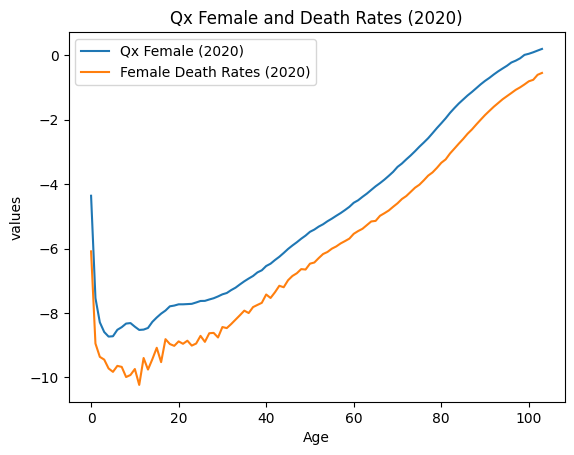

In [145]:
# Plot perbandingan qx_female_final dan death rates 2020

age = italy_2020["Age"].values
sns.lineplot(x=age, y=(np.log(qx_female_2020)), label="Qx Female (2020)")
sns.lineplot(x=age, y=(np.log(italy_2020["Female"].values)), label="Female Death Rates (2020)")

plt.legend()
plt.xlabel("Age")
plt.ylabel("values")
plt.title("Qx Female and Death Rates (2020)")
plt.show()

ARIMA

In [146]:
pivot_table.loc[0:, 1872].values

array([0.23793158, 0.17689156, 0.12207387, 0.07837883, 0.04670596,
       0.02575661, 0.01316076, 0.00646568, 0.00361973, 0.00307119,
       0.00369671, 0.00476498, 0.0057945 , 0.00663594, 0.00722356,
       0.00762596, 0.007935  , 0.00823057, 0.00855917, 0.00897704,
       0.00943259, 0.0099522 , 0.01039557, 0.01076453, 0.01104355,
       0.01130066, 0.01159268, 0.01191762, 0.01224173, 0.01257008,
       0.01278733, 0.01312259, 0.0132735 , 0.0133078 , 0.01324133,
       0.01321728, 0.01340451, 0.01375904, 0.01410876, 0.01440831,
       0.01453413, 0.01487357, 0.01501834, 0.01501894, 0.01483673,
       0.01472057, 0.01494768, 0.01542996, 0.01606857, 0.01692282,
       0.01794523, 0.01956331, 0.02116825, 0.02270046, 0.02401433,
       0.02547951, 0.02748269, 0.02994448, 0.0325579 , 0.03538401,
       0.03832848, 0.04258288, 0.04682674, 0.05091806, 0.05476242,
       0.05911973, 0.06478787, 0.07109198, 0.07721295, 0.08318537,
       0.08933323, 0.09893327, 0.10968429, 0.12100472, 0.13156

In [151]:
# Inisialisasi Series kosong
qx_all = pd.Series(dtype=float)
tahun = 1872

# Loop untuk menggabungkan data setiap tahun
for i in range(147):
    data = pivot_table.loc[:, tahun].values  # Ambil data berdasarkan tahun
    qx_all = pd.concat([qx_all, pd.Series(data)], ignore_index=True)  # Gabungkan ke Series
    tahun += 1

# Output hasil
print(qx_all)

0        0.237932
1        0.176892
2        0.122074
3        0.078379
4        0.046706
           ...   
15283    1.013160
15284    1.049588
15285    1.099472
15286    1.159449
15287    1.220713
Length: 15288, dtype: float64


2019

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=-22883.369, Time=1.11 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=10038.064, Time=0.18 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=-22835.932, Time=0.15 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=-4441.804, Time=0.51 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=-22888.436, Time=0.43 sec
 ARIMA(0,0,2)(0,0,0)[0]             : AIC=-12062.773, Time=0.85 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=-22883.782, Time=0.35 sec
 ARIMA(1,0,3)(0,0,0)[0]             : AIC=-22893.407, Time=0.54 sec
 ARIMA(0,0,3)(0,0,0)[0]             : AIC=-15787.696, Time=0.75 sec
 ARIMA(2,0,3)(0,0,0)[0]             : AIC=-22899.117, Time=1.28 sec
 ARIMA(3,0,3)(0,0,0)[0]             : AIC=-22898.045, Time=1.11 sec
 ARIMA(2,0,4)(0,0,0)[0]             : AIC=-22901.773, Time=0.79 sec
 ARIMA(1,0,4)(0,0,0)[0]             : AIC=-22904.102, Time=0.41 sec
 ARIMA(0,0,4)(0,0,0)[0]             : AIC=-18220.966, Time=1.12 sec
 ARIMA(

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_1618/2744589426.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


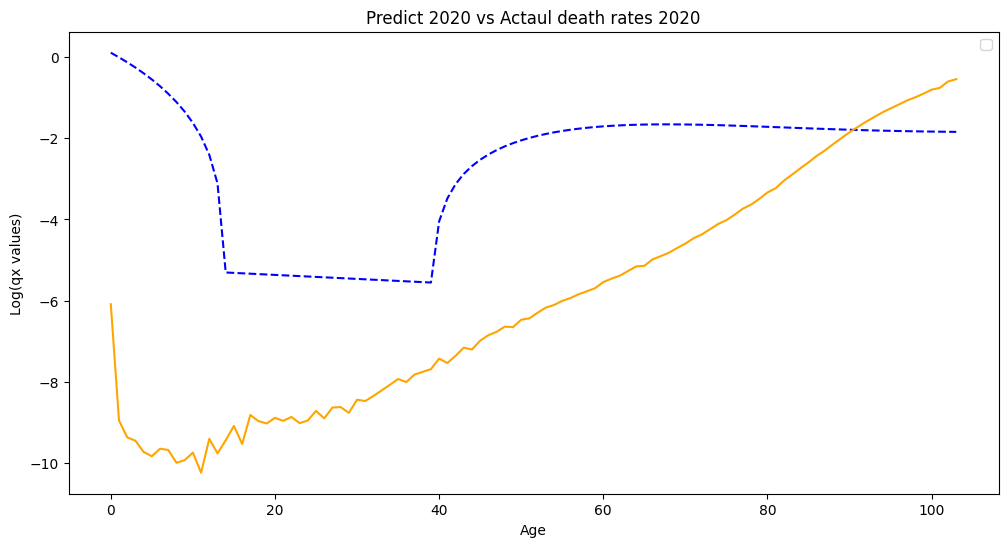

In [152]:
from pmdarima import auto_arima
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Auto arima 2019
arima_2019 = auto_arima(qx_all, seasonal=False, trace=True, error_action='ignore', suppress_warnings=True)
print(f"Best order selected by auto_arima: {arima_2019.order}")

# Forecast 2020
forecast_2020 = arima_2019.predict(n_periods=104)

# Extract actual death rates for females in 2019 and 2021 from Italy dataset
italy_2020_female = italy_2020["Female"].values

# Get age values for plotting
age_2020 = italy_2020["Age"].values

# Plotting
plt.figure(figsize=(12, 6))

# Plot predict 2020
sns.lineplot(x=age_2020, y=np.log(forecast_2020), color="blue", linestyle="--")

# Plot actual death rates 2020
sns.lineplot(x=age_2020, y=np.log(italy_2020_female), color="orange")

# Add labels and title
plt.xlabel("Age")
plt.ylabel("Log(qx values)")
plt.title("Predict 2020 vs Actaul death rates 2020")

# Show legend
plt.legend()
plt.show()


Performing stepwise search to minimize aic
 ARIMA(2,2,2)(0,0,0)[0] intercept   : AIC=-727.789, Time=0.13 sec
 ARIMA(0,2,0)(0,0,0)[0] intercept   : AIC=-671.696, Time=0.01 sec
 ARIMA(1,2,0)(0,0,0)[0] intercept   : AIC=-692.235, Time=0.01 sec
 ARIMA(0,2,1)(0,0,0)[0] intercept   : AIC=-694.753, Time=0.01 sec
 ARIMA(0,2,0)(0,0,0)[0]             : AIC=-673.025, Time=0.01 sec
 ARIMA(1,2,2)(0,0,0)[0] intercept   : AIC=-649.108, Time=0.04 sec
 ARIMA(2,2,1)(0,0,0)[0] intercept   : AIC=-732.872, Time=0.04 sec
 ARIMA(1,2,1)(0,0,0)[0] intercept   : AIC=-709.652, Time=0.03 sec
 ARIMA(2,2,0)(0,0,0)[0] intercept   : AIC=-734.405, Time=0.02 sec
 ARIMA(3,2,0)(0,0,0)[0] intercept   : AIC=-733.489, Time=0.05 sec
 ARIMA(3,2,1)(0,0,0)[0] intercept   : AIC=-730.468, Time=0.10 sec
 ARIMA(2,2,0)(0,0,0)[0]             : AIC=-731.329, Time=0.01 sec

Best model:  ARIMA(2,2,0)(0,0,0)[0] intercept
Total fit time: 0.489 seconds
Best order selected by auto_arima: (2, 2, 0)


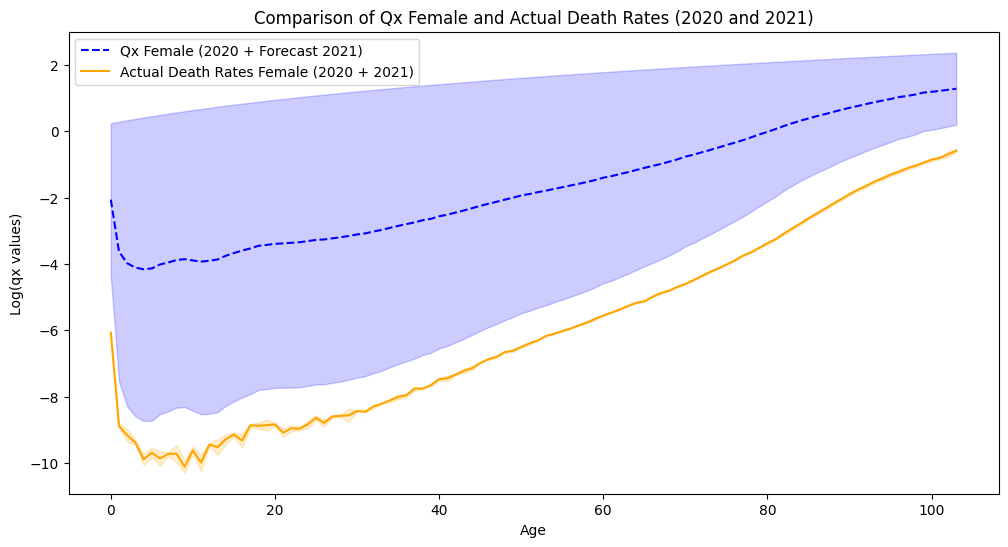

In [46]:
from pmdarima import auto_arima
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Auto arima 2019
auto_model_2019 = auto_arima(qx_female_2019, seasonal=False, trace=True, error_action='ignore', suppress_warnings=True)
print(f"Best order selected by auto_arima: {auto_model_2019.order}")

# Auto arima 2020
auto_model = auto_arima(qx_female_2020, seasonal=False, trace=True, error_action='ignore', suppress_warnings=True)
print(f"Best order selected by auto_arima: {auto_model.order}")

# Forecast using the best ARIMA model for 104 periods (for 2021)
forecast = auto_model.predict(n_periods=104)

# Extract actual death rates for females in 2020 and 2021 from Italy dataset
italy_2020_female = italy_2020["Female"].values
italy_2021_female = italy_2021["Female"].values

# Get age values for plotting
age_2020 = italy_2020["Age"].values
age_2021 = italy_2021["Age"].values

# Concatenate data for continuous lines
age_combined = np.concatenate([age_2020, age_2021])
qx_female_combined = np.concatenate([np.log(qx_female_2020), np.log(forecast)])  # Log transformation for consistency
italy_female_combined = np.concatenate([np.log(italy_2020_female), np.log(italy_2021_female)])

# Plotting
plt.figure(figsize=(12, 6))

# Plot combined qx_female (2020 and forecasted 2021)
sns.lineplot(x=age_combined, y=qx_female_combined, label="Qx Female (2020 + Forecast 2021)", color="blue", linestyle="--")

# Plot combined actual death rates (2020 and 2021)
sns.lineplot(x=age_combined, y=italy_female_combined, label="Actual Death Rates Female (2020 + 2021)", color="orange")

# Add labels and title
plt.xlabel("Age")
plt.ylabel("Log(qx values)")
plt.title("Comparison of Qx Female and Actual Death Rates (2020 and 2021)")

# Show legend
plt.legend()
plt.show()
